In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyRTC.utils as utils
from pyRTC import *
from astropy.io import fits

import sys
sys.path.append('..')

Spinnaker python SDK installation not found
Spinnaker python SDK installation not found
ximea python SDK installation not found
PI python SDK installation not found


In [2]:
shm_names = ["wfs", "wfsRaw", "wfc", "wfc2D", "wfcShape", "signal", "signal2D", "psfShort", "psfLong", "wfsInfo", "loop", "refSlopes", "subApMasks", "cmat", "m2c"] #list of SHMs to reset
clear_shms(shm_names)

Opening Existing Shared Memory Object wfs
Opening Existing Shared Memory Object wfs_meta
Opening Existing Shared Memory Object wfs_meta
Closing wfs
Creating New Shared Memory Object wfs_gpu_handle
Opening Existing Shared Memory Object wfs_gpu_handle_meta
Closing wfs_meta
Opening Existing Shared Memory Object wfsRaw
Opening Existing Shared Memory Object wfsRaw_meta
Closing wfs_gpu_handle
Opening Existing Shared Memory Object wfsRaw_meta
Closing wfsRaw
Creating New Shared Memory Object wfsRaw_gpu_handle
Opening Existing Shared Memory Object wfsRaw_gpu_handle_meta
Closing wfsRaw_meta
Creating New Shared Memory Object wfc
Creating New Shared Memory Object wfc_meta
Closing wfsRaw_gpu_handle
Opening Existing Shared Memory Object wfc_meta
Closing wfc
Creating New Shared Memory Object wfc_gpu_handle
Opening Existing Shared Memory Object wfc_gpu_handle_meta
Closing wfc_meta
Creating New Shared Memory Object wfc2D
Creating New Shared Memory Object wfc2D_meta
Closing wfc_gpu_handle
Opening Existi

## NOMAD test

In [ ]:
from ..gui.nomad import *
import numpy as np

In [ ]:
def calc_exposure_time(Vmag, felix_filter="clear_5"):
    t0 = 0.2
    V0 = 8.5

    fratio = 10**(-0.4*(Vmag - V0))

    if Vmag < 12:
        coadds = 5
    else:
        coadds = 1
        
    texpos = t0 / fratio / coadds # flux limited
    
    return texpos, coadds

In [49]:
texpos, coadds = calc_exposure_time(8.5)
print(texpos, coadds, texpos*coadds)

0.04 5 0.2


In [7]:
output = run_t3io("info", "SPr")
ra_rad, dec_rad = float(output[1]), float(output[2])

felix_dew, felix_dns = get_felix_xyoffset()
felix_dew /= 206265
felix_dns /= 206265

results, err_code = nomad_search_pos(
    ra = ra_rad + felix_dew, # radians
    dec = dec_rad + felix_dns,
    radius = 40 / 206265,
    nomad_root = "/starcatalogs4/nomad/",
    maximum = 20,
    enable_mag_limit = False,
    mag_limit = 16,
    debug=False
)

In [9]:
name_brightest = ""
Vmin = 999

for record in results:
    print(record.name)
    for i in range(4):
        mag_filter = record.magD[i]
        mag = record.mag[i]
        if mag_filter != "-":
            print(f"  {mag_filter} = {mag:.2f}")
        if mag_filter == "V":
            if mag < Vmin:
                Vmin = mag
                name_brightest = record.name

if Vmin < 999:
    print(name_brightest, '{:.2f}'.format(Vmin))
else:
    print("No guide stars found within a 40\" radius.")

NOMAD1_00117-0652503
  V = 11.82
  B = 12.62
  R = 11.30
  J = 9.35
NOMAD1_00117-0652497
  V = 15.57
  B = 15.44
  R = 15.40
  J = 15.06
NOMAD1_00117-0652475
  B = 20.00
  R = 19.20
NOMAD1_00117-0652500
  R = 19.22
NOMAD1_00117-0652467
  B = 17.53
  R = 17.48
  J = 16.73
NOMAD1_00117-0652509
  V = 13.41
  B = 13.76
  R = 12.04
  J = 12.48
NOMAD1_00117-0652496
  R = 19.55
NOMAD1_00117-0652501
  B = 20.12
  R = 19.25
NOMAD1_00117-0652463
  B = 19.57
  R = 18.51
  J = 16.61
NOMAD1_00117-0652489
  B = 17.65
  R = 17.16
NOMAD1_00117-0652516
  V = 16.10
  B = 16.73
  R = 15.94
  J = 15.16
NOMAD1_00117-0652462
  B = 19.28
  R = 18.82
NOMAD1_00117-0652514
  B = 20.82
  R = 19.15
NOMAD1_00117-0652503 11.82


## Init hardware

In [11]:
#conf = utils.read_yaml_file("../config/temp/config_felixsim.yaml")
conf = utils.read_yaml_file("../config/temp/config_felix.yaml")
slopes_conf = conf["slopes"]
dm_conf = conf["wfc"]
loop_conf = conf["loop"]
wfs_conf = conf["wfs"]

#wfs = AndorWFS(wfs_conf)
wfs = FELIXSimulator(wfs_conf)
slopes = SlopesProcess(conf=slopes_conf)
dm = ImakaDM(dm_conf)
loop = Loop(loop_conf)

Opening Existing Shared Memory Object wfsInfo
Opening Existing Shared Memory Object wfsInfo_meta
Opening Existing Shared Memory Object wfsRaw
Opening Existing Shared Memory Object wfsRaw_meta
Thread expose: Priority set to REALTIME
Opening Existing Shared Memory Object wfs
Opening Existing Shared Memory Object wfs_meta
Opening Existing Shared Memory Object simInjectedSlopes_meta
Closing simInjectedSlopes_meta
Opening Existing Shared Memory Object simInjectedSlopes
Opening Existing Shared Memory Object simInjectedSlopes_meta


FileNotFoundError: [Errno 2] No such file or directory: '/Users/ellenlee/Documents/pyRTC-IRTF/IRTF/calib/felixcal/calpts_32.npy'

In [3]:
wfs.start()
slopes.start()
dm.start()
dm.flatten()

loop.setGain(0.)
loop.leakyGain = 0.0
loop.start()

In [5]:
wfs.setExposure(0.1)

In [17]:
wfs.setRoi([64,64,122,389])

In [10]:
wfs.setRoi([64,64,179,232])

In [4]:
wfs.setRoi([64,64,350,322])

In [11]:
wfs.setExposure(0.03)

In [12]:
wfs.closeShutter()

In [13]:
wfs.darkCount = 100
wfs.takeDark()

In [14]:
wfs.openShutter()

ref1

In [21]:
name = "alcyone-3"
utdate = "20251006"
fname = f"/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/data/{utdate}/refSlopes/{name}.npy"

In [16]:
slopes.refSlopeCount = 500
slopes.takeRefSlopes()
slopes.saveRefSlopes(fname)

In [22]:
slopes.loadRefSlopes(fname)

In [23]:
loop.setGain(0.)
loop.leakyGain = 0.02

In [18]:
loop.setNumDroppedModes(0)

In [13]:
wfs.setExposure(0.007)
wfs.coadds = 1
loop.setNumDroppedModes(0)

In [76]:
wfs.closeShutter()
time.sleep(0.5)
wfs.darkCount = 500
wfs.takeDark()
time.sleep(0.5)
wfs.openShutter()

In [70]:
wfs.setExposure(0.1)
wfs.coadds = 5
loop.setNumDroppedModes(5)

In [71]:
wfs.closeShutter()
time.sleep(0.5)
wfs.darkCount = 10
wfs.takeDark()
time.sleep(0.5)
wfs.openShutter()

In [52]:
loop.start()

In [27]:
dm.flatten()

In [15]:
loop.setGain(0.2)
loop.leakyGain = 0.02

In [16]:
loop.setGain(0.)
loop.leakyGain = 0.02

In [18]:
wfs.showAvailableReadout()

Function GetNumberADChannels returned 20002 number of available channels 1
Function GetNumberHSSpeeds 20002 number of available speeds 4
Available HSSpeeds in MHz [17.0, 10.0, 5.0, 1.0] 
Function GetNumberVSSpeeds 20072 number of available speeds 0
Available VSSpeeds in us []
Recommended VSSpeed 0.0 index 0
Function GetNumberAmp returned 20002 number of amplifiers 2
Available amplifier modes ['ElectronMultiplying', 'Conventional']


In [50]:
loop.stop()

In [11]:
loop.loadIM("/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/imat/imat.poke.20251002.c.npy")

In [24]:
loop.loadIM("/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/imat/imat.docrime.lag0.20251006.a.npy")

In [67]:
slopes.loadRefSlopes(fname)
coeffs = np.array([0,0,0, 0,0, 0,-0.2])
slopes.refSlopes += np.reshape(loop.IM @ coeffs, (4,2))

## Run loop

In [30]:
loop.stop()

In [45]:
loop.loadPlaybackBuffer("/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/pb/cacofoni_pb_189Hz_x378_nmodes7_amp1_fmin4_df0.5.npy")

In [17]:
loop.setGain(0)
loop.leakyGain = 0.0
loop.start()

In [51]:
dm.flatten()

In [50]:
loop.pbGain = 0.0

In [24]:
loop.saveIM("/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/imat/imat.docrime.lag0.20251006.a.npy")

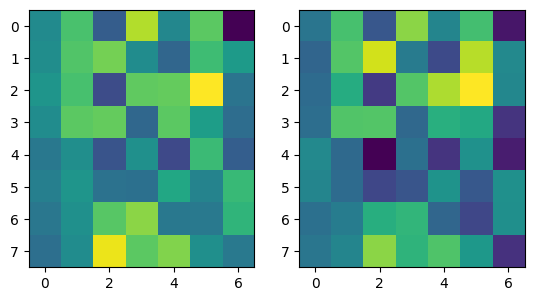

In [23]:
oldim = np.load("/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/imat/imat.poke.20251002.c.npy")
newim = loop.IM.copy()

fig,axs = plt.subplots(nrows=1,ncols=2)
axs[0].imshow(oldim)
axs[1].imshow(newim)

In [39]:
loop.loadIM()

In [47]:
loop.numItersIM = 3000
loop.pokeAmp = 0.2

In [20]:
dm.flatten()

In [48]:
loop.docrimeIM(lag=1)

In [22]:
loop.computeCM()

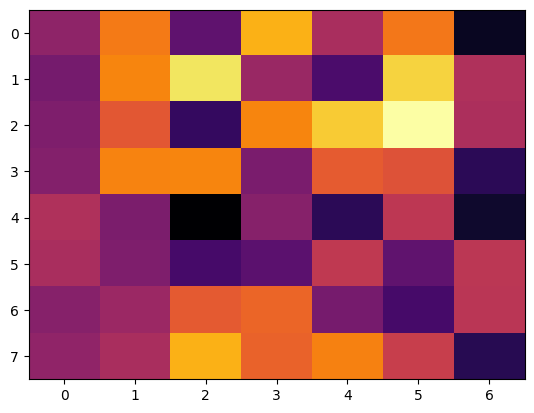

In [25]:
loop.plotIM()

In [34]:
loop.IMMethod = 0#"docrime"
loop.computeIM()
dm.flatten()

In [19]:
loop.loadIM("calib/imat/imat.poke.20251002.c.npy")

In [11]:
loop.setNumDroppedModes(0)

In [38]:
loop.stop()

In [32]:
dm.flatten()

In [13]:
slopes.refSlopeCount = 1000
slopes.takeRefSlopes()

In [15]:
loop.stop()

In [23]:
loop.setGain(0.)
loop.leakyGain = 0.0
loop.start()

In [18]:
slopes.loadChopMasks("/Users/ellenlee/Documents/pyRTC-IRTF/IRTF/calib/felixcal/masks_itp.fits")

FileNotFoundError: [Errno 2] No such file or directory: '/Users/ellenlee/Documents/pyRTC-IRTF/IRTF/calib/felixcal/masks_itp.fits'

In [67]:
slopes.refSlopeCount = 1000
slopes.takeRefSlopes()

In [76]:
slopes.loadRefSlopes()
#coeffs = np.array([0,0,0,0,0,0,0])
#coeffs = np.array([0,0,-0.1, 0.2,0.1, 0,-0.2])
coeffs = np.array([0,0,-0.1, 0.2,0.1, 0.1,-0.3])
#coeffs = np.array([0,0,0, 0,0, 0,0])
slopes.refSlopes += np.reshape(loop.IM @ coeffs, (4,2))

In [23]:
wfs.setRoi([100,100,65,10])

In [28]:
coeffs = np.zeros(7)
amp = 0
coeffs[0] = amp
coeffs[1] = amp
loop.sendToWfc(coeffs)
#dm.sendToHardware()

In [ ]:
loop.start()

In [26]:
loop.stop()

In [84]:
loop.setGain(0.)
loop.leakyGain = 0.02
loop.start()
slopes.loadSubApMasks("/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/felixcal/masks_itp_posM.fits")

In [83]:
n_chop = 1000
freq = 1
amp = 3.1
maskA = "/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/felixcal/masks_itp_posA.fits"
maskB = "/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/felixcal/masks_itp_posB.fits"
masksAB = [maskA, maskB]

for i in range(n_chop):

    sgn = 1
    for j in range(2):
        loop.setGain(0)
        loop.leakyGain = 0
        loop.stop()
        time.sleep(0.01)
        coeffs = np.zeros(7) # Go to A
        coeffs[0] = amp * sgn
        coeffs[1] = amp * sgn
        loop.sendToWfc(coeffs)

        slopes.loadSubApMasks(masksAB[j])
        time.sleep(0.01)
        
        loop.start()        
        loop.setGain(0.3)
        loop.leakyGain = 0.02
        time.sleep(1/freq/2)

        sgn *= -1

loop.setGain(0)
loop.leakyGain = 0.02
slopes.loadSubApMasks("/home/felix/src/pyrtc/pyRTC-IRTF/IRTF/calib/felixcal/masks_itp_posM.fits")

KeyboardInterrupt: 

In [46]:
loop.stop()

In [55]:
slopes.chopSubApsToPosition("BA",2)

In [87]:
slopes.chopSubaps(freq=0.25,rampFraction=0.25,numIter=1)

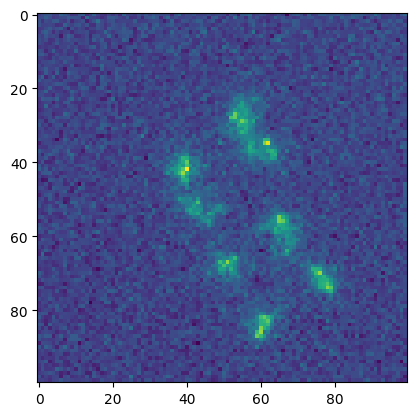

In [19]:
img = img1 + img2
wfs.stop()
plt.figure()
plt.imshow(img)
plt.show()
fits.writeto("../pyRTCView/felix_image.fits", img, overwrite=True)